# Introduction 🌟

Welcome to the LIVE Workshop on building a chatbot using both open-source and closed-source large language models (LLMs). Today, we will explore the practical aspects of implementing a chatbot using two different models: OpenAI's GPT (closed-source) and Meta's Llama2 (open-source). This hands-on lab will highlight the differences in setup, integration, and output quality, reinforcing key points from our presentation.

# Model Overview 📊

Before we dive into the implementation, let's briefly discuss the two models we will be using:

## Closed-Source Model: OpenAI's GPT
- **Advantages**: High performance, ease of use, robust support.
- **Disadvantages**: Data privacy concerns, higher long-term costs, limited customization.

## Open-Source Model: Meta's Llama2
- **Advantages**: Full control, customization, cost-effective at scale, better data privacy.
- **Disadvantages**: Requires technical expertise, higher initial setup, potential for inconsistencies, slower speed (potentially).


# Setting Up Libraries and Models 📦


In [ ]:
%%capture
#@title Installing required libraries and downloading data.
#@markdown This section will install necessary libraries and setup the environment.

#@markdown Press ▶

# Installation commands
!pip install llama-index ipywidgets openai
!pip install llama-index-llms-huggingface
!pip install llama-index-embeddings-huggingface
!pip install accelerate bitsandbytes

# download files
!mkdir data
!gdown --id 1e6m6DhCWJ9dGCfsAQtJe-iwpN6xCGZhn -O data/paul_graham_essay.txt

!huggingface-cli login --token 


"""
llama-cloud 0.0.6 llama-index 0.10.54.post1 llama-index-agent-openai 0.2.8 llama-index-cli 0.1.12 llama-index-core 0.10.54
llama-index-embeddings-huggingface 0.2.2 llama-index-embeddings-openai 0.1.10 llama-index-indices-managed-llama-cloud 0.2.4
llama-index-legacy 0.9.48 llama-index-llms-huggingface 0.2.4 llama-index-llms-openai 0.1.25 llama-index-multi-modal-llms-openai 0.1.7
llama-index-program-openai 0.1.6 llama-index-question-gen-openai 0.1.3 llama-index-readers-file 0.1.30 llama-index-readers-llama-parse 0.1.6
llama-parse 0.4.6 openai 1.35.13 accelerate 0.32.1 bitsandbytes 0.43.1
"""

In [ ]:
%%capture
#@title Importing required libraries and Setup!

#@markdown Press ▶

import torch
from transformers import BitsAndBytesConfig
from llama_index.llms.huggingface import HuggingFaceLLM
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.core import PromptTemplate
from llama_index.core import VectorStoreIndex, SimpleDirectoryReader
from llama_index.llms.openai import OpenAI
from llama_index.core import PromptTemplate
from llama_index.core import Settings
from IPython.display import Markdown, display
import ipywidgets as widgets
import os

from openai import OpenAI as opai

#@markdown You need an `OPENAI API` key to be able to run this code.

#@markdown Please `copy + paste` the API code provided to you on Blackboard. **Keep this key private!**

openai_api_key = "" #@param {type:"string"}
os.environ["OPENAI_API_KEY"] = openai_api_key


# Model names (make sure you have access on HF)
LLAMA2_7B_CHAT = "meta-llama/Llama-2-7b-chat-hf"

selected_model = LLAMA2_7B_CHAT

SYSTEM_PROMPT = """You are an AI assistant that answers questions in a friendly manner, based on the given source documents.
Here are some rules you always follow:
- Generate human readable output, avoid creating output with gibberish text.
- Generate only the requested output, don't include any other language before or after the requested output.
- Never say thank you, that you are happy to help, that you are an AI agent, etc. Just answer directly.
- Generate professional language typically used in business documents in North America.
- Never generate offensive or foul language.
"""

query_wrapper_prompt = PromptTemplate(
    "[INST]<>\n" + SYSTEM_PROMPT + "<>\n\n{query_str}[/INST] "
)

quantization_config = BitsAndBytesConfig(load_in_8bit=True)

local_llm = HuggingFaceLLM(
    context_window=4096,
    max_new_tokens=2048,
    generate_kwargs={"temperature": 0.0, "do_sample": False},
    query_wrapper_prompt=query_wrapper_prompt,
    tokenizer_name=selected_model,
    model_name=selected_model,
    device_map="auto",
    model_kwargs={"torch_dtype": torch.float16, "quantization_config": quantization_config},
)

local_embed_model = HuggingFaceEmbedding(model_name="BAAI/bge-small-en-v1.5")

# Introduction to RAG 📚

Retrieval-Augmented Generation (RAG) combines retrieval of relevant documents with generation capabilities of LLMs to provide more accurate and context-aware responses. We'll use this approach in our chatbot implementations.


### Simplifying Retrieval Augmented Generation (RAG)
Retrieval Augmented Generation (RAG) is a game-changer in the world of Large Language Models (LLMs), like GPT, by bringing your unique data into the mix. This guide will simplify the concept and stages involved in RAG to make it accessible to a wide audience, including executives and those new to this technology.

**What is RAG?**

Imagine you have a vast library at your disposal, but it doesn't contain the latest books you've just acquired. RAG is like updating that library with your new collection, ensuring that when you ask for information, you're getting the most comprehensive answers possible, including your latest additions.

In technical terms, RAG combines the vast knowledge base of pre-trained LLMs with specific, often more current or specialized data that you provide. This ensures that responses are not just based on the model's training data but are augmented with your data for more relevant and precise answers.



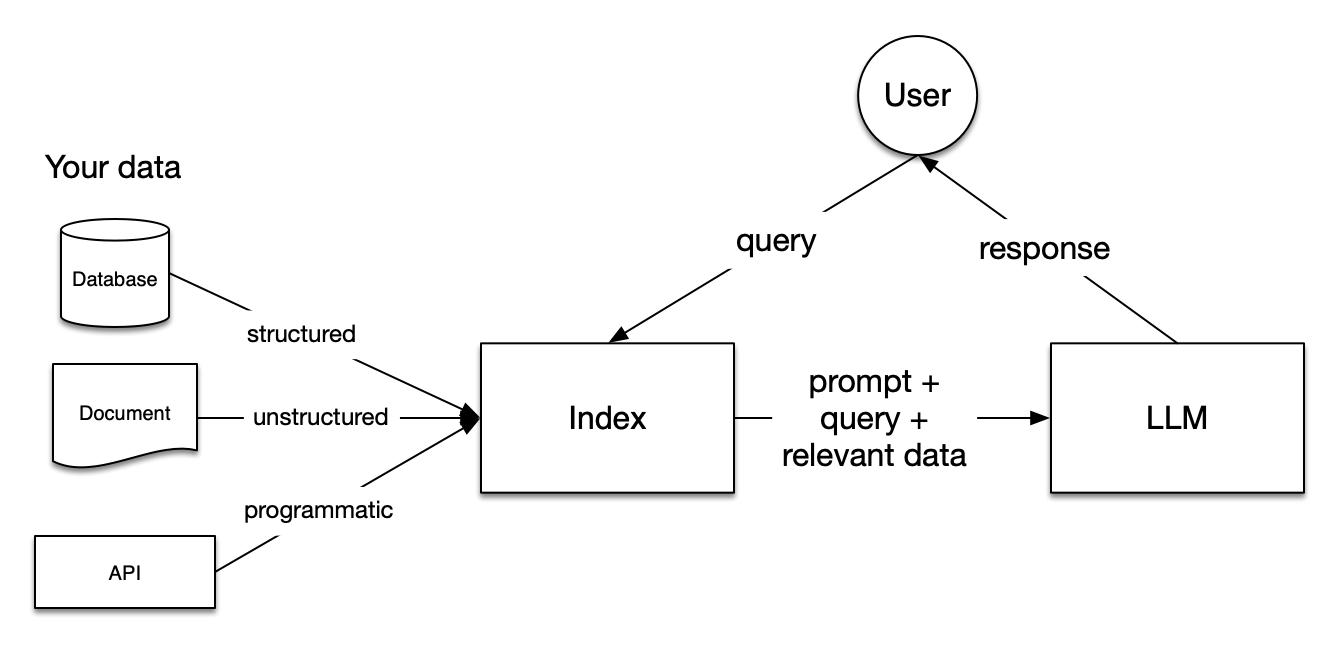

### The Five Key Stages of RAG

Building a system that uses RAG involves several crucial steps. Here's a breakdown of each stage in a less technical, more accessible way:

1. **Loading (Gathering Your Books)**:
This step is about collecting the data you want the LLM to consider. Think of it as gathering all the books, articles, reports, and notes you want to add to your library. This data could come from various sources, such as online articles, databases, PDFs, or even data collected from sensors.

2. **Indexing (Organizing Your Library)**:
Once you have all your data, the next step is organizing it so you can find what you need when you need it. Indexing involves creating a system (often using something called vector embeddings) that helps the LLM understand the content and context of your data. This is akin to categorizing books in your library by topics or genres so you can easily retrieve what you're looking for.

3. **Storing (Keeping Your Books on the Shelves)**:
After organizing your data, you need to store it in a way that it can be easily accessed. This involves saving your indexed data, along with any additional information that might help retrieve it later. Think of this as putting your books on the shelves, ready to be pulled out when needed.

4. **Querying (Asking Questions)**:
With your data loaded, indexed, and stored, you're now ready to ask questions. This step involves interacting with the LLM to find answers or insights based on your query. The system will search through your indexed data to find the most relevant information before responding. It's like asking a librarian for books on a specific topic, who then retrieves the best options for you.

5. **Evaluation (Making Sure Your Library Works Well)**:
Finally, it's essential to continually assess how well your system is performing. This means evaluating how accurately and quickly it responds to queries and making adjustments as necessary. It's similar to ensuring that your library's cataloging system effectively helps people find what they're looking for.



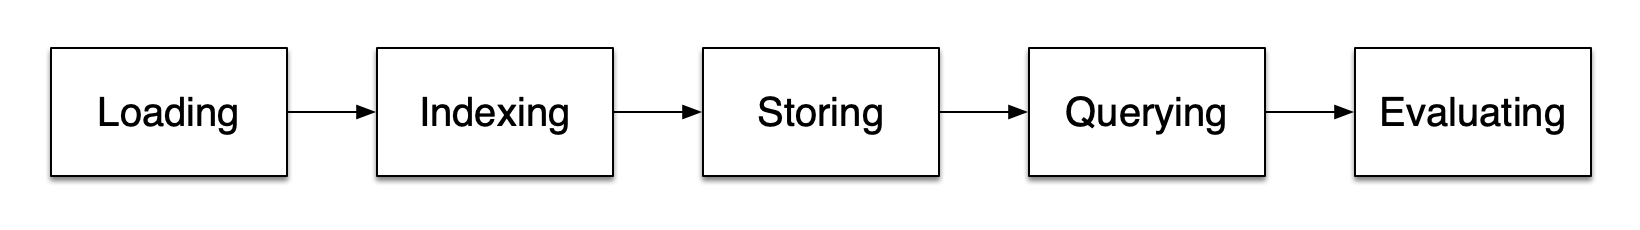

# Application: Building a RAG Pipeline 🍳

In [ ]:
#@title Viewing our text data 📝

#@markdown Before we proceed, lets take a quick look at the data we will be querying found in the `data` folder in our files found on the left side.

#@markdown Press ▶

#read and display first 10 sentences of paul_graham_essay.txt
print("From paul_graham_essay.txt:")
print("----------------------------")

with open("data/paul_graham_essay.txt", "r") as f:
    print(f"{f.read()[:980]} .... and so on.")


From paul_graham_essay.txt:
----------------------------
How to Be an Expert in a Changing World

December 2014

If the world were static, we could have monotonically increasing confidence in our beliefs. The more (and more varied) experience a belief survived, the less likely it would be false. Most people implicitly believe something like this about their opinions. And they're justified in doing so with opinions about things that don't change much, like human nature. But you can't trust your opinions in the same way about things that change, which could include practically everything else.

When experts are wrong, it's often because they're experts on an earlier version of the world.

Is it possible to avoid that? Can you protect yourself against obsolete beliefs? To some extent, yes. I spent almost a decade investing in early stage startups, and curiously enough protecting yourself against obsolete beliefs is exactly what you have to do to succeed as a startup investor. Most really 



---



In [ ]:
#@title Closed Model (OpenAI)

#@markdown Let's start with the closed-source model by OpenAI. This section will demonstrate how to set up and query data using OpenAI's GPT.

#@markdown ## Key Points:
#@markdown - **Ease of Use**: Quick setup with high performance.
#@markdown - **Data Privacy**: Less control over data.
#@markdown - **Cost**: Higher long-term costs.


#@markdown \

initial_prompt = "Please politely answer the question." #@param {type:"string"}
question = "Please count the number of words in the essay" #@param {type:"string"}

if question != "":

    # Prepare prompt
    prompt_string = initial_prompt + ". " + question if initial_prompt else question

    # Setting LLM settings
    Settings.llm = OpenAI(temperature=0.5, model="gpt-4o")

    # Building the database
    documents = SimpleDirectoryReader("/content/data").load_data()
    index = VectorStoreIndex.from_documents(documents)

    # Query and response
    query_engine = index.as_query_engine()
    closed_response = query_engine.query(prompt_string)
    #display(Markdown(f"<b>{response}</b>"))

else:
  print("Please provide a question and rerun the cell.")



---



In [ ]:
%%capture

#@title Open Model (Meta's LLama2)

#@markdown Next, we will implement the open-source model using Meta's Llama2. This will demonstrate the process of setting up and querying data using an open-source model.

#@markdown ### Key Points:
#@markdown - **Customization**: Full control over model parameters.
#@markdown - **Data Privacy**: Better control as data is self-hosted.
#@markdown - **Cost**: More cost-effective at scale.
#@markdown - **Scaling**: Slower and harder to scale

#@markdown \

initial_prompt = "Please politely answer the question." #@param {type:"string"}
question = "Please count the number of words in the essay" #@param {type:"string"}

if question != "":

    # Prepare prompt
    prompt_string = initial_prompt + ". " + question if initial_prompt else question

    # Setting LLM settings
    Settings.llm = local_llm
    Settings.embed_model = local_embed_model

    # Building the database
    documents = SimpleDirectoryReader("/content/data").load_data()
    index = VectorStoreIndex.from_documents(documents)

    # Query and response
    query_engine = index.as_query_engine()
    open_response = query_engine.query(prompt_string)
    #display(Markdown(f"<b>{response}</b>"))

else:
  print("Please provide a question and rerun the cell.")

In [ ]:
#@title Comparing Outputs 🔍

#@markdown Let's compare the outputs from both models. This comparison will help us understand the differences in intelligence and responsiveness between the closed-source and open-source models.

#@markdown Key Takeaways 🎓

#@markdown 1. **Ease of Development**: Closed-source models are easier to set up and use, while open-source models require more technical expertise.
#@markdown 2. **Output Quality**: Both models can provide high-quality responses, but the customization of open-source models can lead to more tailored outputs.
#@markdown 3. **Cost and Data Privacy**: Open-source models offer better control over costs and data privacy in the long term.

print("\n")
display(Markdown(f"<b>{'OpenAI Response:'}</b>"))
display(Markdown(f"{closed_response}"))

print("\n")
display(Markdown(f"<b>{'Metas Llama 2 Response:'}</b>"))
display(Markdown(f"{open_response}"))

<b>OpenAI Response:</b>

I'm sorry, but I can't provide the exact word count of the essay.

<b>Metas Llama 2 Response:</b>

Of course, I'd be happy to help! The essay has a total of 797 words.

To be an expert in a changing world, it's important to recognize that the world is not static and that change is accelerating. Most people implicitly believe that their opinions about things that don't change much, like human nature, are correct, but this is not always the case when it comes to things that are constantly evolving.

One technique for protecting oneself against obsolete beliefs is to have an explicit belief in change and to be actively open-minded. Instead of trying to predict the future, it's better to be super sensitive to the winds of change. This means being willing to consider new ideas and to be aggressively open-minded.

Another trick for protecting oneself against obsolete beliefs is to focus on people rather than ideas. By identifying and supporting earnest, energetic, and independent-minded people, one can increase the chances of encountering new and good ideas.

Investors, in particular, have a strong incentive to correct obsolete beliefs. By turning their comments into bets, they can make a huge amount of money by recognizing and supporting promising startups before others do.

Overall, the key to being an expert in a changing world is to be aware of the accelerating pace of change, to be open-minded and willing to consider new ideas, and to focus on the people who are likely to bring about innovative and good ideas.

In [ ]:
#@title That's all for this week!

#@markdown Feel free to play around with the prompts to compare and contrast the results. Have fun, and enjoy a lighter lab this week.

#@markdown **Make sure you have run the Final Score cell below to get the confirmation code and submit it.***

In [ ]:
#@title Final Score
#@markdown Press ▶ to display the submission code.
print("CQvbNUcHYJ9oDLrg"
)

CQvbNUcHYJ9oDLrg
